# Residual estimation and adaptive refinement
First solve a localized diffusion problem with a known solution on the unit square, adapted from Larson and Bengzon, *The Finite Element Method: Theory, Implementation, and Practice* (2010 notes), §4.9.3, printed pp. 90–92, especially Eq. (4.130) on p. 91. Compare the residual estimator with the actual energy error, then use its element contributions to refine the mesh.

An additional example solves the Poisson problem on an L-shaped domain. We will examine where the mesh becomes finer. Its exact solution is unknown, so we cannot compute effectivity for that example.

Use the **Python (Finite Elements)** kernel. Saved outputs show a completed run. Restart the kernel and run the cells in order to repeat it. The notebook uses one MPI process through `MPI.COMM_SELF`.

**Class sequence:** one solve → compute indicators → mark → refine and solve again → repeat → compare with uniform refinement. Plotting functions are collected at the top; the finite element operations remain visible below.


## Setup and plotting
Run these cells first. The macOS compiler selection is explained in [environment/README.md](../../environment/README.md). Plotting functions are collapsed so that the numerical method is easier to follow.


In [1]:
import os
import sys
from pathlib import Path

if sys.platform == "darwin" and Path("/usr/bin/clang").exists():
    os.environ.setdefault("CC", "/usr/bin/clang")
    os.environ.setdefault("LDSHARED", "/usr/bin/clang -bundle -undefined dynamic_lookup")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import ufl
import dolfinx
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import fem, mesh, plot
from dolfinx.fem.petsc import LinearProblem

plt.rcParams.update({"font.size": 16, "axes.titlesize": 17})
print("DOLFINx:", dolfinx.__version__)


DOLFINx: 0.11.0


In [2]:
def mesh_triangles(domain):
    cells, _, coordinates = plot.vtk_mesh(domain)
    return mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:]
    )

def draw_mesh(ax, domain, title, marked=None, zoom=None):
    triangles = mesh_triangles(domain)
    if marked is not None:
        colors = np.zeros(len(triangles.triangles))
        colors[marked] = 1
        ax.tripcolor(triangles, facecolors=colors, cmap="Blues", vmin=0, vmax=1.8)
    ax.triplot(triangles, color="0.25", linewidth=0.35)
    ax.set(title=title, xlabel=r"$x_1$", ylabel=r"$x_2$")
    ax.set_aspect("equal")
    if zoom is not None:
        ax.set_xlim(-zoom, zoom)
        ax.set_ylim(-zoom, zoom)

def show_state(domain, V, u_h, eta_squared):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.1), layout="constrained")
    fig.get_layout_engine().set(wspace=0.12)
    draw_mesh(axes[0], domain, "Current mesh")
    cells, _, coordinates = plot.vtk_mesh(V)
    triangles = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:]
    )
    solution = axes[1].tripcolor(triangles, u_h.x.array.real, shading="gouraud")
    axes[1].set(title=r"FE solution $u_h$", xlabel=r"$x_1$", ylabel=r"$x_2$")
    axes[1].set_aspect("equal")
    fig.colorbar(solution, ax=axes[1], shrink=0.8)
    indicators = axes[2].tripcolor(
        mesh_triangles(domain), facecolors=np.sqrt(eta_squared), cmap="magma",
        edgecolors="0.35", linewidth=0.2,
    )
    axes[2].set(title=r"Element indicators $\eta_e$", xlabel=r"$x_1$", ylabel=r"$x_2$")
    axes[2].set_aspect("equal")
    fig.colorbar(indicators, ax=axes[2], shrink=0.8)
    return fig

def show_refinement(old_domain, new_domain, marked):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
    draw_mesh(axes[0], old_domain, "Marked elements (blue)", marked)
    draw_mesh(axes[1], new_domain, "Mesh after refinement")
    return fig

def show_mesh_history(domains, cycles):
    fig, axes = plt.subplots(1, len(cycles), figsize=(13.5, 4), layout="constrained")
    for ax, cycle in zip(axes, cycles):
        count = domains[cycle].topology.index_map(2).size_local
        draw_mesh(ax, domains[cycle], f"Cycle {cycle}: {count} elements")
    return fig


def show_verification(adaptive_dofs, adaptive_eta, adaptive_error,
                      uniform_dofs, uniform_eta, uniform_error):
    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    ax.loglog(uniform_dofs, uniform_error, "s-", color="tab:orange",
                  label="Uniform: energy error")
    ax.loglog(adaptive_dofs, adaptive_error, "o-", color="tab:blue",
                  label="Adaptive: energy error")
    ax.loglog(uniform_dofs, uniform_eta, "s--", color="tab:orange",
                  label=r"Uniform: estimator $\eta$")
    ax.loglog(adaptive_dofs, adaptive_eta, "o--", color="tab:blue",
                  label=r"Adaptive: estimator $\eta$")
    ax.set(title="Error and estimator", ylabel="Energy error or estimator",
           xlabel="Total scalar FE degrees of freedom")
    ax.legend(fontsize=13)
    ax.grid(True, which="both", alpha=0.25)

    fig_effectivity, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    ax.semilogx(uniform_dofs, np.array(uniform_eta) / uniform_error,
                     "s-", color="tab:orange", label="Uniform")
    ax.semilogx(adaptive_dofs, np.array(adaptive_eta) / adaptive_error,
                     "o-", color="tab:blue", label="Adaptive")
    ax.set(title="Effectivity", ylabel=r"$I_{\mathrm{eff}}=\eta/\|u-u_h\|_a$",
           xlabel="Total scalar FE degrees of freedom")
    ax.legend()
    ax.grid(True, which="both", alpha=0.25)
    return fig, fig_effectivity


## 1. A localized solution on the unit square
Let $\Omega=(0,1)^2$ and solve
$$
-\Delta u=f\quad\text{in }\Omega,\qquad u=0\quad\text{on }\partial\Omega.
$$
Use $\alpha=400$, $s_i=x_i-\tfrac12$, $G_i=\exp(-\alpha s_i^2)$, and $c=\exp(-\alpha/4)$. Choose
$$
u_{\rm ex}(x_1,x_2)=(G_1-c)(G_2-c),
$$
$$
f(x_1,x_2)=-\Delta u_{\rm ex}
=2\alpha\left[(1-2\alpha s_1^2)G_1(G_2-c)
 +(1-2\alpha s_2^2)G_2(G_1-c)\right].
$$
On each boundary edge, one factor $G_i-c$ is zero, so the exact solution satisfies the prescribed values.

The factors $G_i-c$ make Larson's Gaussian pulse exactly zero on the boundary. UFL differentiates the expression for $u_{\rm ex}$ to obtain $f$.

The narrow Gaussian pulse needs enough integration points even on a coarse mesh. We use degree-20 quadrature for the volume integrals. This sets the integration rule, not the polynomial degree of the $P_1$ finite elements.


In [3]:
quadrature_degree = 20

def create_square_mesh():
    domain = mesh.create_unit_square(MPI.COMM_SELF, 8, 8)
    domain.topology.create_entities(1)
    return domain

def pulse_data(domain):
    x = ufl.SpatialCoordinate(domain)
    alpha = 400.0
    c = np.exp(-alpha / 4.0)
    G1 = ufl.exp(-alpha * (x[0] - 0.5)**2)
    G2 = ufl.exp(-alpha * (x[1] - 0.5)**2)
    u_exact = (G1 - c) * (G2 - c)
    f = -ufl.div(ufl.grad(u_exact))
    return u_exact, f

domain = create_square_mesh()
u_exact, f = pulse_data(domain)


## 2. Solve on the initial mesh
Use continuous piecewise-linear functions:
$$
\mathcal V_{h,0}
=\{v_h\in H^1_0(\Omega):v_h|_{\mathcal K_e}\in P_1(\mathcal K_e)\}.
$$
Define the bilinear and linear forms
$$
a(w,v)=\int_\Omega\nabla w\cdot\nabla v\,dx,
\qquad \ell(v)=\int_\Omega fv\,dx.
$$
Find $u_h\in\mathcal V_{h,0}$ such that
$$
a(u_h,v_h)=\ell(v_h)\quad\forall v_h\in\mathcal V_{h,0}.
$$
In two dimensions, FEniCSx identifies edges by dimension 1 and elements by dimension 2. `create_connectivity(1, 2)` records which elements touch each edge. We then find the exterior edges and prescribe zero at their degrees of freedom.

`LinearProblem` assembles and solves the variational problem. Its LU options select a direct linear solver. The scalar space `V` includes boundary degrees of freedom, whose values are prescribed by `bc`.

FEniCSx uses `cell` in its API and zero-based array indices; these are elements in our mathematical notation.


In [4]:
def solve_diffusion(domain, f):
    domain.topology.create_connectivity(1, 2)
    V = fem.functionspace(domain, ("Lagrange", 1))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)

    boundary_facets = mesh.exterior_facet_indices(domain.topology)
    boundary_dofs = fem.locate_dofs_topological(V, 1, boundary_facets)
    bc = fem.dirichletbc(PETSc.ScalarType(0.0), boundary_dofs, V)

    a = ufl.inner(ufl.grad(trial), ufl.grad(test)) * ufl.dx
    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    L = f * test * dx
    problem = LinearProblem(
        a, L, bcs=[bc], petsc_options_prefix="residual_diffusion_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    )
    u_h = problem.solve()
    return V, u_h

V, u_h = solve_diffusion(domain, f)
print("Elements:", domain.topology.index_map(2).size_local)
print("Total scalar FE degrees of freedom:", V.dofmap.index_map.size_global)


Elements: 128
Total scalar FE degrees of freedom: 81


## 3. Compute the residual indicators
Since $u_h$ is linear on each triangle and $k=1$,
$$
r_e=f+\Delta u_h=f,\qquad
j_{\mathcal F}
=-\left(\nabla u_h^+\cdot\mathbf n^+
       +\nabla u_h^-\cdot\mathbf n^-\right).
$$
The normals point outward from the two neighboring elements. UFL's `jump(grad(u_h), normal)` computes their sum.

The local and global estimators are exactly those used in the lecture:
$$
\eta_e^2=h_e^2\int_{\mathcal K_e}r_e^2\,dx
+\frac12\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                       \mathcal F\ {\rm interior}}}
h_{\mathcal F}\int_{\mathcal F}j_{\mathcal F}^2\,ds.
$$
Sum the squared indicators to obtain the global estimator:
$$
\eta=\left(\sum_e\eta_e^2\right)^{1/2}.
$$
Here $h_e$ is element diameter and $h_{\mathcal F}$ is edge length. There is no Neumann term because all boundary values are prescribed.

### One assembled entry per element
The discontinuous constant space `DG0` has one basis function $z_e$ per element, equal to 1 there and 0 elsewhere.

The PDE solution still uses continuous $P_1$ elements. DG0 is used only to assemble the element indicators; this does not make the PDE discretization a discontinuous Galerkin method. Although $u_h$ is continuous, its gradient can jump between elements, which is why the facet term appears in the estimator.

- Integrating $h^2r^2z_e$ gives that element's volume contribution.
- On an interior edge, $z_e^+$ and $z_e^-$ are the test-function values from the two neighboring elements. The two half contributions in the code are exactly $h_{\mathcal F}j_{\mathcal F}^2(z_e^++z_e^-)/2$.
- `dS` integrates over interior edges. In 2D, `avg(FacetArea(domain))` is their length.

The assembled entries are already squared indicators: do **not** divide by element area.

`fem.form` prepares an integral for numerical assembly; `assemble_vector` evaluates it against every DG0 test basis function. DG0 degree-of-freedom numbers need not be the geometric element numbers. The final loop retrieves the one DG0 entry belonging to each element, so the arrays used for marking follow element order.


Element contribution to eta^2: 157.079509
Facet contribution to eta^2:   7.886346
Global estimator eta:          12.843903


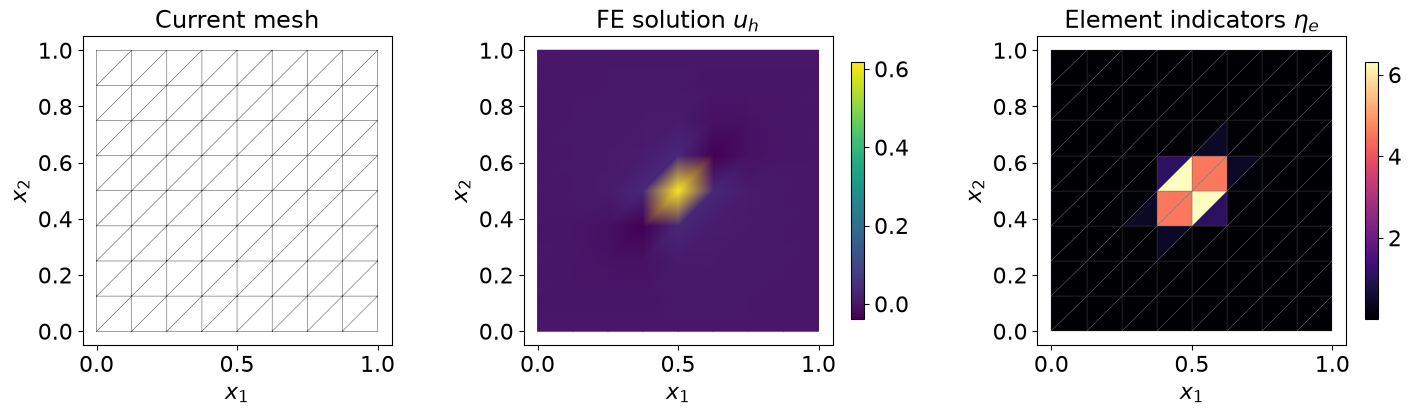

In [5]:
def estimate_error(domain, u_h, f):
    W = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(W)
    h = ufl.CellDiameter(domain)
    h_F = ufl.avg(ufl.FacetArea(domain))
    normal = ufl.FacetNormal(domain)
    r = f + ufl.div(ufl.grad(u_h))
    j = -ufl.jump(ufl.grad(u_h), normal)

    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    element_form = h**2 * r**2 * z * dx
    facet_form = (
        0.5 * h_F * j**2 * z("+") * ufl.dS
        + 0.5 * h_F * j**2 * z("-") * ufl.dS
    )
    element_vector = fem.assemble_vector(fem.form(element_form))
    facet_vector = fem.assemble_vector(fem.form(facet_form))

    count = domain.topology.index_map(2).size_local
    element_part = np.zeros(count)
    facet_part = np.zeros(count)
    for e in range(count):
        dof = W.dofmap.cell_dofs(e)[0]
        element_part[e] = element_vector.array[dof].real
        facet_part[e] = facet_vector.array[dof].real
    return element_part, facet_part

element_part, facet_part = estimate_error(domain, u_h, f)
eta_squared = element_part + facet_part
eta = np.sqrt(np.sum(eta_squared))

print(f"Element contribution to eta^2: {np.sum(element_part):.6f}")
print(f"Facet contribution to eta^2:   {np.sum(facet_part):.6f}")
print(f"Global estimator eta:          {eta:.6f}")
show_state(domain, V, u_h, eta_squared)
plt.show()


## 4. Compare the estimator with the known error
For this verification problem the exact energy error can be integrated:
$$
E_a=\|u_{\rm ex}-u_h\|_a
=\left(\int_\Omega\nabla(u_{\rm ex}-u_h)\cdot
                 \nabla(u_{\rm ex}-u_h)\,dx\right)^{1/2}.
$$
Compare it with the estimator using the effectivity:
$$
I_{\rm eff}=\frac{\eta}{E_a}.
$$
This error calculation uses the analytic $u_{\rm ex}$, not its nodal interpolant. It is only a check on the estimator; marking below does not use the exact solution.


In [6]:
def energy_error(domain, u_h, u_exact):
    error = u_exact - u_h
    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    squared_error = fem.assemble_scalar(fem.form(
        ufl.inner(ufl.grad(error), ufl.grad(error)) * dx
    ))
    return np.sqrt(squared_error)

error = energy_error(domain, u_h, u_exact)
print(f"Energy error: {error:.6f}")
print(f"Estimator:    {eta:.6f}")
print(f"Effectivity:  {eta / error:.3f}")


Energy error: 1.323294
Estimator:    12.843903
Effectivity:  9.706


## 5. Mark elements using the indicators

Dörfler marking selects a set $\mathcal M$ such that
$$
\sum_{\mathcal K_e\in\mathcal M}\eta_e^2
\ge\theta\sum_e\eta_e^2.
$$
Choose $\theta=0.5$: the marked elements must account for at least half of the squared estimator. `argsort` supplies element indices in increasing indicator order; reversing that order puts the largest first. The loop adds elements until their squared indicators reach the target.

The selected elements are identified from the computed residuals; no knowledge of the exact error is used. The table below lists the six largest squared indicators, separated into volume and facet contributions. Compare its first rows with the printed marked-element IDs. IDs in this table are Python's zero-based element indices.


In [7]:
def mark_elements(eta_squared, theta):
    order = np.argsort(eta_squared)[::-1]
    target = theta * np.sum(eta_squared)
    selected_sum = 0.0
    marked = []
    for e in order:
        marked.append(e)
        selected_sum += eta_squared[e]
        if selected_sum >= target:
            break
    return np.array(marked, dtype=np.int32)

theta = 0.5
marked = mark_elements(eta_squared, theta)
fraction = np.sum(eta_squared[marked]) / np.sum(eta_squared)
print(f"Marked {len(marked)} of {len(eta_squared)} elements")
print(f"Fraction of eta^2 selected: {fraction:.3f}")
print("Marked element IDs:", marked)

largest = np.argsort(eta_squared)[::-1][:6]
display(pd.DataFrame({
    "element ID": largest,
    "volume contribution": element_part[largest],
    "facet contribution": facet_part[largest],
    "squared indicator": eta_squared[largest],
}))


Marked 3 of 128 elements
Fraction of eta^2 selected: 0.607
Marked element IDs: [52 75 68]


,element ID,volume contribution,facet contribution,squared indicator
0,52,38.730553,1.053185,39.783738
1,75,38.730553,1.053185,39.783738
2,68,19.633294,0.919753,20.553047
3,60,19.633294,0.919753,20.553047
4,67,19.633294,0.919753,20.553047
5,59,19.633294,0.919753,20.553047


## 6. Refine the marked mesh

DOLFINx refines triangles by splitting specified edges. Find the edges belonging to the marked elements and pass them to `mesh.refine`. The refinement routine can also refine neighboring elements to maintain a conforming mesh.

In `compute_incident_entities(..., marked, 2, 1)`, dimensions 2 and 1 mean: take the marked **elements** and find their **edges**.

After refinement we rebuild the data expressions on the new mesh, solve the PDE again, and recompute the indicators.

Implementation references: Dokken's [adaptive-refinement tutorial, Error-indicator section](https://jsdokken.com/dolfinx-tutorial/chapter2/amr.html#error-indicator) illustrates DG0 assembly and the two half contributions. The [DOLFINx mesh documentation](https://docs.fenicsproject.org/dolfinx/v0.11.0/python/generated/dolfinx.mesh.html#dolfinx.mesh.refine) describes the built-in refinement call used below.


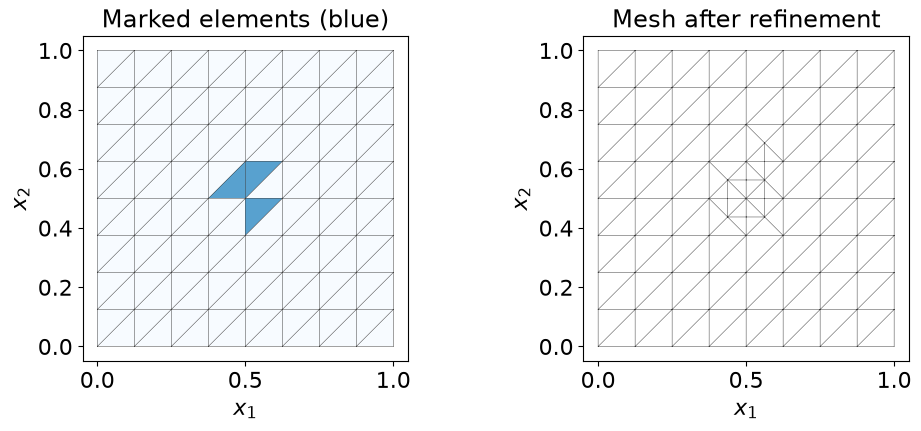

In [8]:
def refine_marked_elements(domain, marked):
    domain.topology.create_connectivity(2, 1)
    edges = mesh.compute_incident_entities(domain.topology, marked, 2, 1)
    refined_domain, _, _ = mesh.refine(domain, edges)
    return refined_domain

refined_domain = refine_marked_elements(domain, marked)
show_refinement(domain, refined_domain, marked)
plt.show()


Energy error: 1.323294 -> 0.760523
Estimator:    12.843903 -> 6.962192


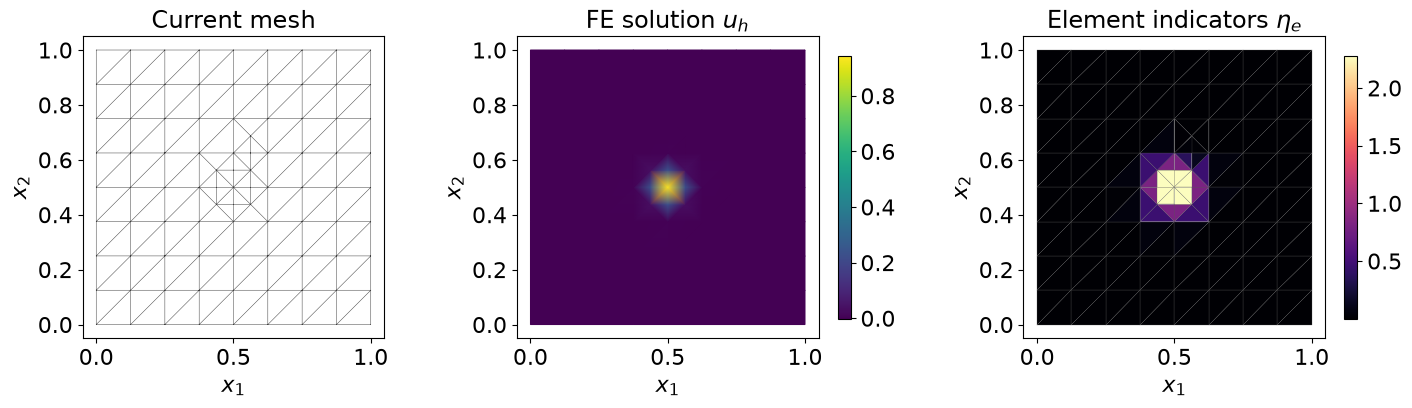

In [9]:
u_exact_new, f_new = pulse_data(refined_domain)
V_new, u_h_new = solve_diffusion(refined_domain, f_new)
element_new, facet_new = estimate_error(refined_domain, u_h_new, f_new)
eta_squared_new = element_new + facet_new
eta_new = np.sqrt(np.sum(eta_squared_new))
error_new = energy_error(refined_domain, u_h_new, u_exact_new)

print(f"Energy error: {error:.6f} -> {error_new:.6f}")
print(f"Estimator:    {eta:.6f} -> {eta_new:.6f}")
show_state(refined_domain, V_new, u_h_new, eta_squared_new)
plt.show()


## 7. Repeat the same adaptive cycle
UFL's spatial coordinate refers to a particular mesh. After refinement, rebuild $u_{\rm ex}$ and $f$ on the new mesh, solve again, and recompute the indicators. The loop below repeats the steps just examined. Nine meshes, numbered 0 through 8, keep the live calculation short.

Reported DOF counts include prescribed boundary degrees of freedom and measure the complete scalar FE space. Marking uses only $\eta_e^2$; the known energy error is recorded for comparison.


,cycle,total DOFs,energy error,estimator,effectivity
0,0,81,1.323294,12.843903,9.706007
1,1,91,0.760523,6.962192,9.154482
2,2,119,0.674145,4.029061,5.976554
3,3,153,0.547252,2.608757,4.767011
4,4,276,0.341499,1.655765,4.848522
5,5,465,0.243102,1.164508,4.790200
6,6,846,0.160621,0.796680,4.960010
7,7,1689,0.110274,0.560247,5.080498
8,8,2869,0.083107,0.411150,4.947265


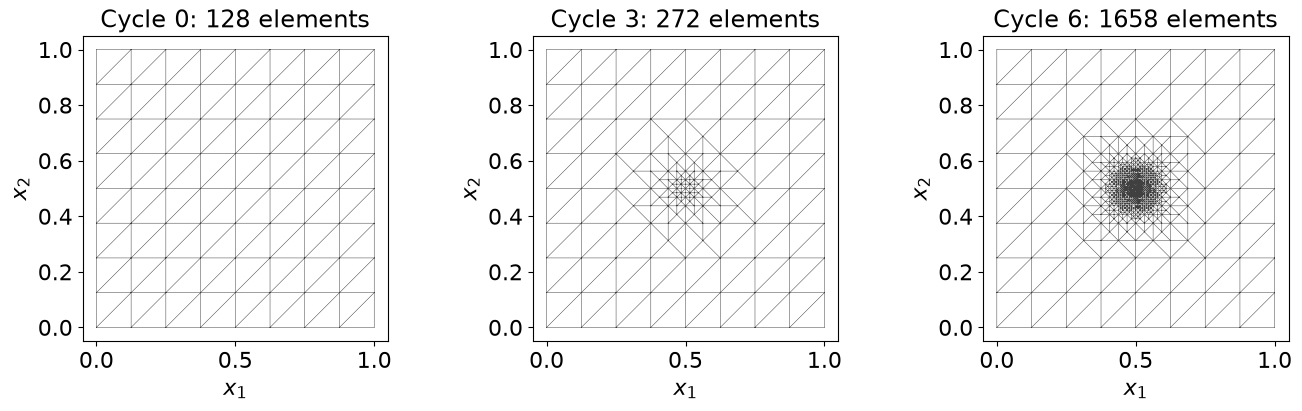

In [10]:
adaptive_domain = create_square_mesh()
adaptive_meshes = []
adaptive_dofs = []
adaptive_eta = []
adaptive_error = []

for cycle in range(9):
    exact_cycle, f_cycle = pulse_data(adaptive_domain)
    V_cycle, u_cycle = solve_diffusion(adaptive_domain, f_cycle)
    element_cycle, facet_cycle = estimate_error(adaptive_domain, u_cycle, f_cycle)
    squared_cycle = element_cycle + facet_cycle

    adaptive_meshes.append(adaptive_domain)
    adaptive_dofs.append(V_cycle.dofmap.index_map.size_global)
    adaptive_eta.append(np.sqrt(np.sum(squared_cycle)))
    adaptive_error.append(energy_error(adaptive_domain, u_cycle, exact_cycle))

    if cycle < 8:
        marked_cycle = mark_elements(squared_cycle, theta)
        adaptive_domain = refine_marked_elements(adaptive_domain, marked_cycle)

display(pd.DataFrame({
    "cycle": range(9),
    "total DOFs": adaptive_dofs,
    "energy error": adaptive_error,
    "estimator": adaptive_eta,
    "effectivity": np.array(adaptive_eta) / adaptive_error,
}))
show_mesh_history(adaptive_meshes, [0, 3, 6])
plt.show()


## 8. Compare with uniform refinement
Start from the same initial mesh and refine every element. Compare against the number of degrees of freedom, not a single $h$: an adaptive mesh has different element sizes in different regions.

Solid curves show the actual energy error; dashed curves show the estimator. The second plot shows their ratio. An effectivity near a constant need not be near 1.


,uniform level,total DOFs,energy error,estimator
0,0,81,1.323294,12.843903
1,1,289,0.760451,6.926259
2,2,1089,0.620598,3.700994
3,3,4225,0.329934,1.917800
4,4,16641,0.166056,0.969069


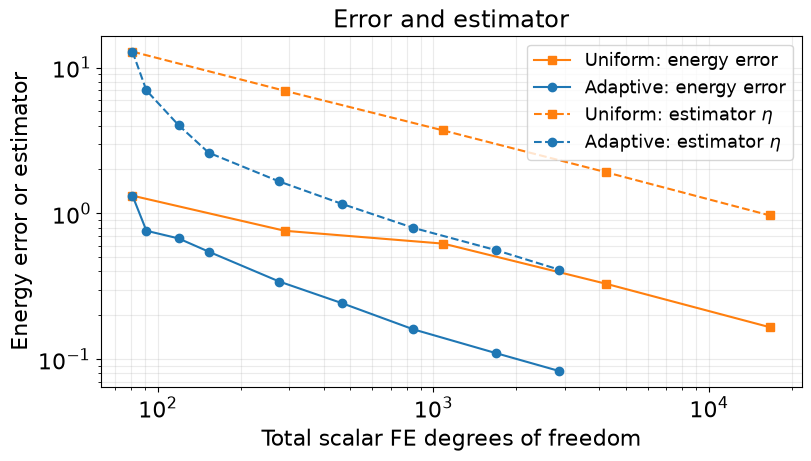

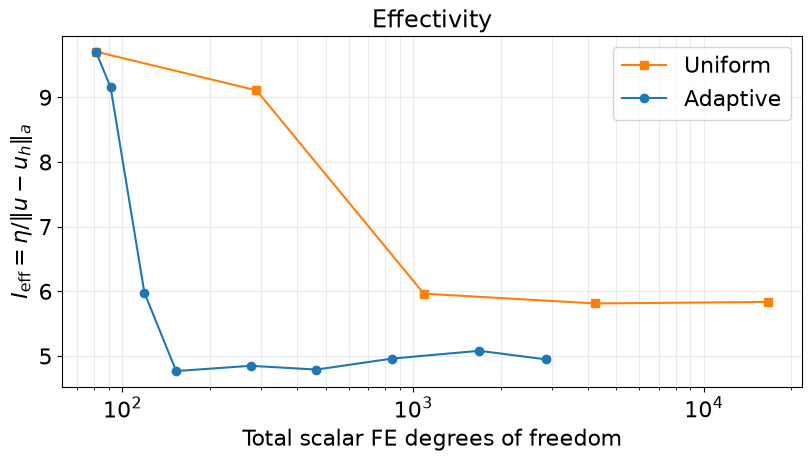

In [11]:
uniform_domain = create_square_mesh()
uniform_dofs = []
uniform_eta = []
uniform_error = []

for level in range(5):
    exact_uniform, f_uniform = pulse_data(uniform_domain)
    V_uniform, u_uniform = solve_diffusion(uniform_domain, f_uniform)
    element_uniform, facet_uniform = estimate_error(uniform_domain, u_uniform, f_uniform)
    uniform_dofs.append(V_uniform.dofmap.index_map.size_global)
    uniform_eta.append(np.sqrt(np.sum(element_uniform + facet_uniform)))
    uniform_error.append(energy_error(uniform_domain, u_uniform, exact_uniform))
    if level < 4:
        uniform_domain, _, _ = mesh.refine(uniform_domain)

display(pd.DataFrame({
    "uniform level": range(5),
    "total DOFs": uniform_dofs,
    "energy error": uniform_error,
    "estimator": uniform_eta,
}))
show_verification(adaptive_dofs, adaptive_eta, adaptive_error,
                  uniform_dofs, uniform_eta, uniform_error)
plt.show()


### Interpreting the results
The adaptive meshes put smaller elements near the pulse. At comparable DOF counts, their actual energy errors are smaller than those from uniform refinement in this run.

The estimator and the actual error both decrease, but their values differ. Their ratio, the effectivity, is about five on the finer adaptive meshes. This is consistent with a reliability bound containing a constant $C_{\rm rel}$; the estimator is not required to equal the error.

The exact solution is used only to measure error. The marking step uses the residual indicators alone.


## Additional example: an L-shaped domain
Remove the lower-right quadrant from $(-1,1)^2$ and solve
$$
-\Delta u=1\quad\text{in }\Omega,\qquad u=0\quad\text{on }\partial\Omega.
$$
The reentrant corner reduces solution regularity. The residual estimate does not require $u\in H^2(\Omega)$.

Construct a square grid aligned with the coordinate axes and retain the triangles outside the lower-right quadrant. No triangle crosses those axes. The geometry helper below uses FEniCSx's `create_submesh` to retain the selected elements.

Use the same solver, estimator, marking, and refinement functions. Here $r_e=1$, so the volume contribution is exactly $h_e^2|\mathcal K_e|$; retain the facet contribution as before. The exact solution is unknown, so do not report a true error or effectivity.

Reference: Arnold, *Lecture Notes on Numerical Analysis of Partial Differential Equations*, Chapter 4, §§9.3–9.5, especially printed p. 74.


In [12]:
def create_l_shaped_mesh(n=2):
    square = mesh.create_rectangle(
        MPI.COMM_SELF,
        [np.array([-1.0, -1.0]), np.array([1.0, 1.0])],
        [2 * n, 2 * n],
        cell_type=mesh.CellType.triangle,
    )
    elements = np.arange(square.topology.index_map(2).size_local, dtype=np.int32)
    centers = mesh.compute_midpoints(square, 2, elements)
    keep = ~((centers[:, 0] > 0.0) & (centers[:, 1] < 0.0))
    domain, _, _, _ = mesh.create_submesh(square, 2, elements[keep])
    domain.topology.create_entities(1)
    return domain

corner_domain = create_l_shaped_mesh()


Estimator: 1.394330 -> 0.178198


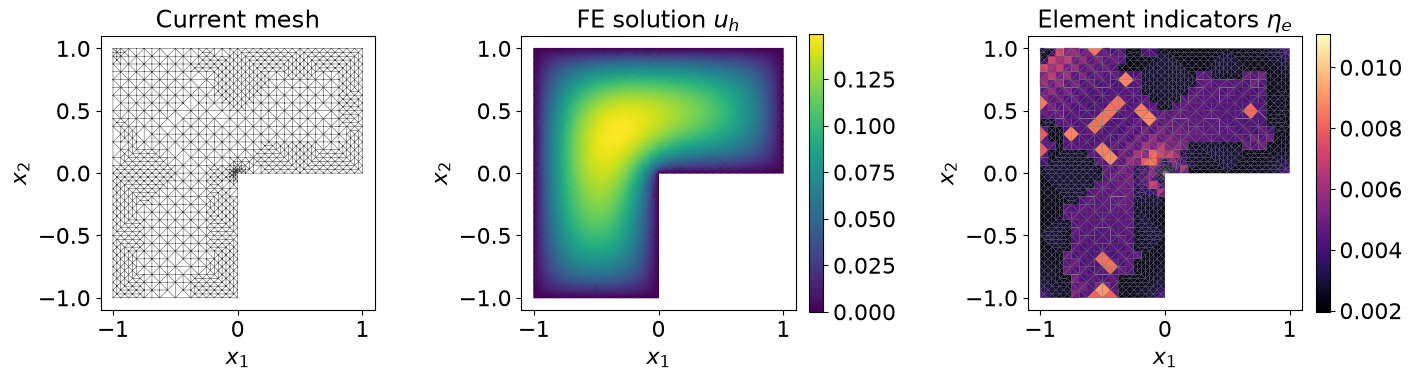

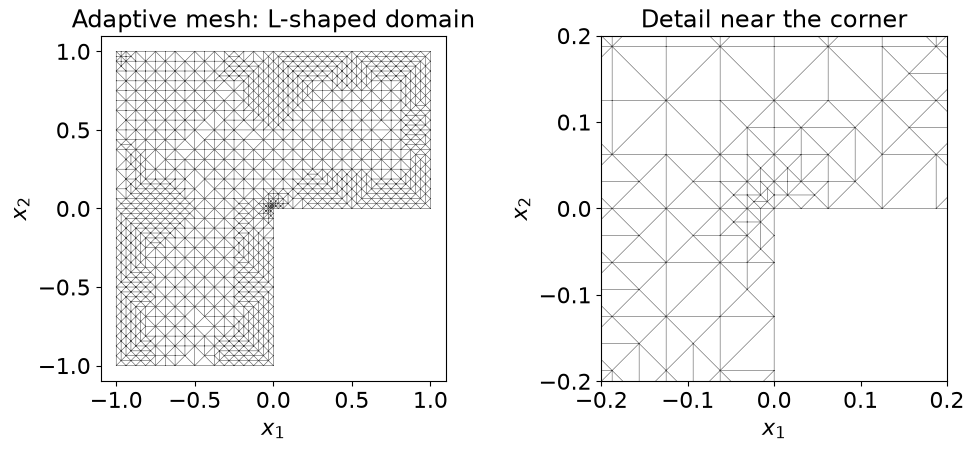

In [13]:
corner_eta = []

for cycle in range(7):
    f_corner = fem.Constant(corner_domain, PETSc.ScalarType(1.0))
    V_corner, u_corner = solve_diffusion(corner_domain, f_corner)
    element_corner, facet_corner = estimate_error(corner_domain, u_corner, f_corner)
    squared_corner = element_corner + facet_corner
    corner_eta.append(np.sqrt(np.sum(squared_corner)))
    if cycle < 6:
        marked_corner = mark_elements(squared_corner, theta)
        corner_domain = refine_marked_elements(corner_domain, marked_corner)

print(f"Estimator: {corner_eta[0]:.6f} -> {corner_eta[-1]:.6f}")
show_state(corner_domain, V_corner, u_corner, squared_corner)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
draw_mesh(axes[0], corner_domain, "Adaptive mesh: L-shaped domain")
draw_mesh(axes[1], corner_domain, "Detail near the corner", zoom=0.2)
plt.show()


The indicators lead to smaller elements near the corner without prescribing where refinement should occur. We can report the decreasing estimator and inspect the mesh, but the exact energy error remains unknown.

Both examples use the same estimator and the same **solve → estimate → mark → refine** loop. In a calculation with an estimator tolerance $\varepsilon_{\rm est}$, stop when $\eta\le\varepsilon_{\rm est}$ or a specified resource limit is reached. The fixed cycle counts above keep this demonstration short.
